<a href="https://colab.research.google.com/github/ngin10/air_fare_predictor/blob/main/air_fare_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv('/content/Clean_Dataset.csv')

In [3]:
df.head(2)

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [5]:
df[df['duration'].isna()]

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price


In [6]:
df.dropna(inplace=True)
df = df[df['class'] == 'Economy']   # keep economy flights only (dataset also has Business class)
print(df.shape)

(206666, 12)

In [7]:
df['price'].agg(['min','max','mean','median','std'])

min        1105.000000
max       42349.000000
mean       6572.342383
median     5772.000000
std        3743.519517
Name: price, dtype: float64

<Axes: xlabel='price', ylabel='Density'>

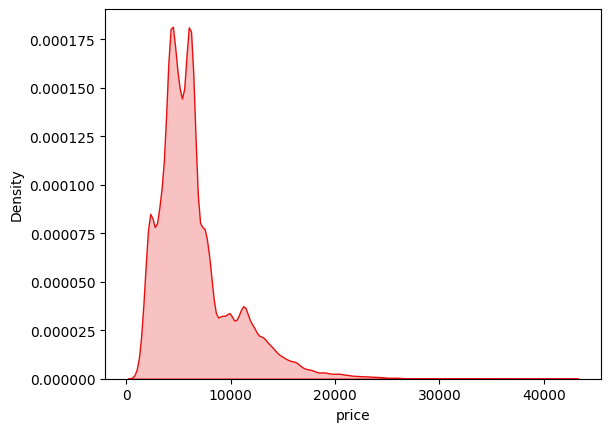

In [8]:
sns.kdeplot(df['price'],fill=True,color='#e80e0e')

<Axes: ylabel='price'>

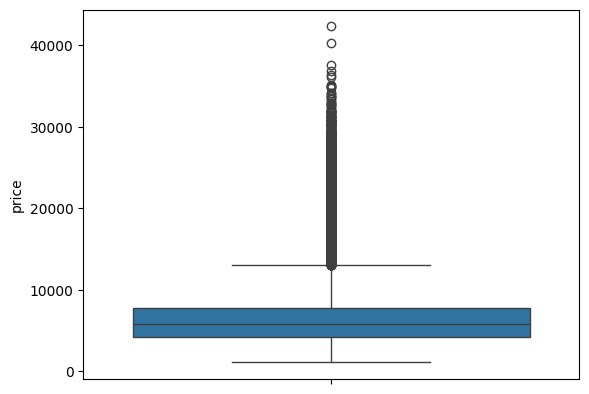

In [9]:
sns.boxplot(df['price'])

In [10]:
price=df[df['price']>14000]

In [11]:
price['source_city'].value_counts().reset_index()

,source_city,count
0,Kolkata,2191
1,Delhi,1844
2,Mumbai,1832
3,Chennai,1815
4,Bangalore,1758
5,Hyderabad,1057


<Axes: xlabel='count', ylabel='source_city'>

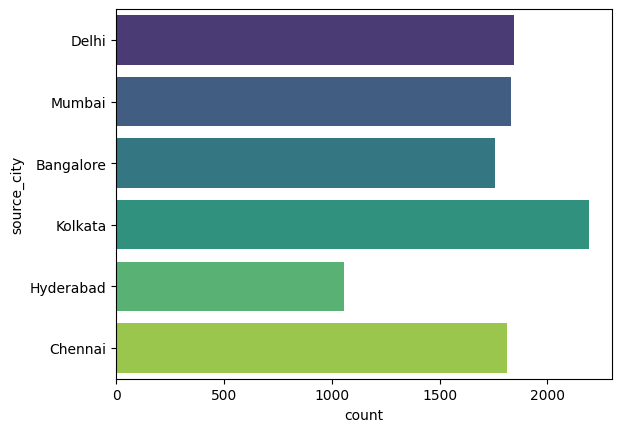

In [12]:
sns.countplot(price['source_city'],palette='viridis')

In [13]:
price['destination_city'].value_counts().reset_index()

,destination_city,count
0,Kolkata,2253
1,Chennai,1892
2,Mumbai,1831
3,Bangalore,1755
4,Delhi,1665
5,Hyderabad,1101


<Axes: xlabel='count', ylabel='destination_city'>

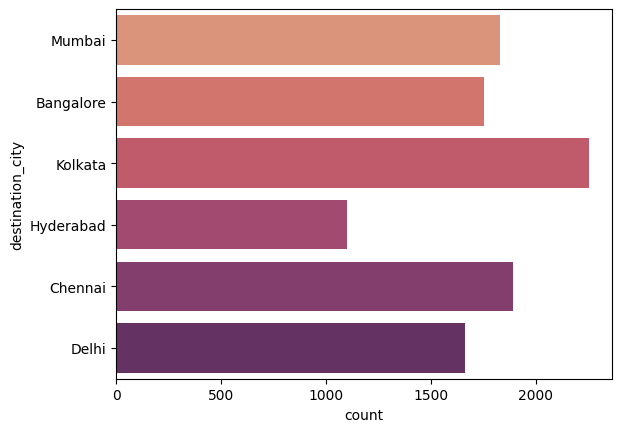

In [14]:
sns.countplot(price['destination_city'],palette='flare')

<Axes: xlabel='price', ylabel='Density'>

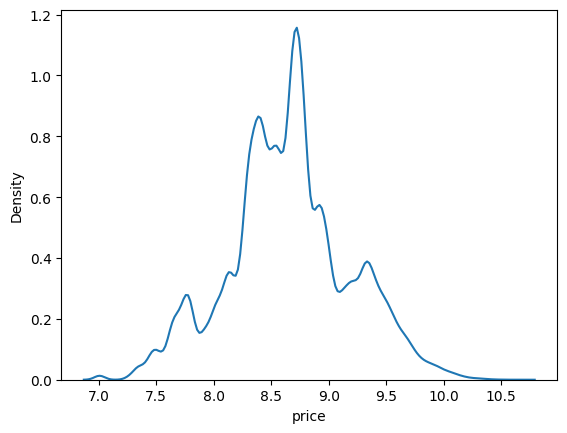

In [15]:
sns.kdeplot(np.log1p(df['price']))

In [16]:
day=df['days_left'].value_counts().reset_index()

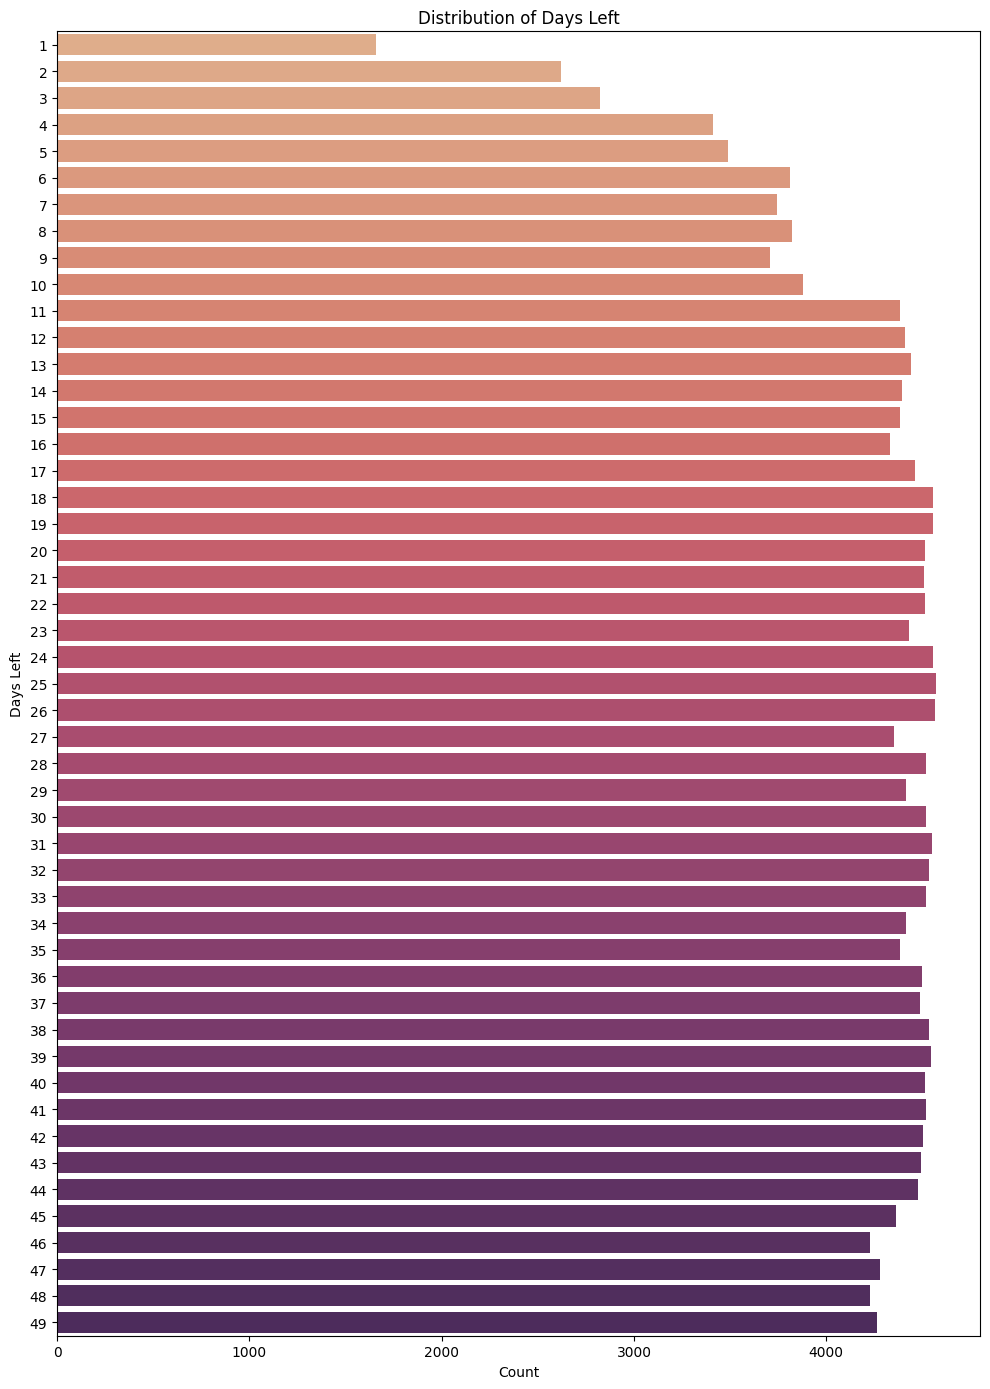

In [17]:

plt.figure(figsize=(10, 14))  # Increase width and height
sns.barplot(data=day, y=day['days_left'].sort_values(ascending=False), x='count', palette='flare', orient='h')
plt.xlabel('Count')
plt.ylabel('Days Left')
plt.title('Distribution of Days Left')
plt.tight_layout()
plt.show()

In [18]:
day.agg(['min','max','mean','median','std'])

,days_left,count
min,1.00000,1661.000000
max,49.00000,4571.000000
mean,25.00000,4217.673469
median,25.00000,4430.000000
std,14.28869,571.108403


<Axes: xlabel='days_left', ylabel='Density'>

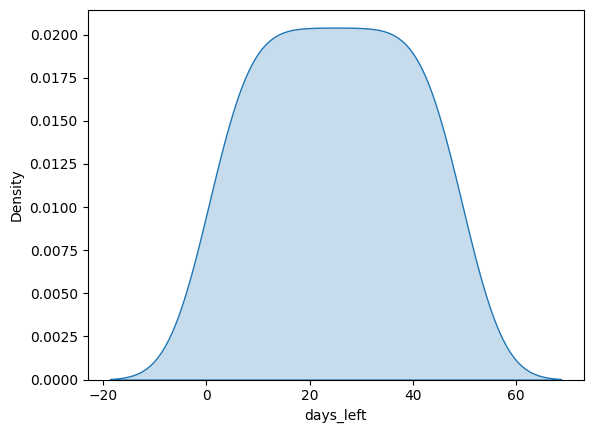

In [19]:
sns.kdeplot(day['days_left'],fill=True)

In [20]:
corr1=df[['price','days_left']]

In [21]:
corr1.corr()

,price,days_left
price,1.000000,-0.559551
days_left,-0.559551,1.000000


<Axes: >

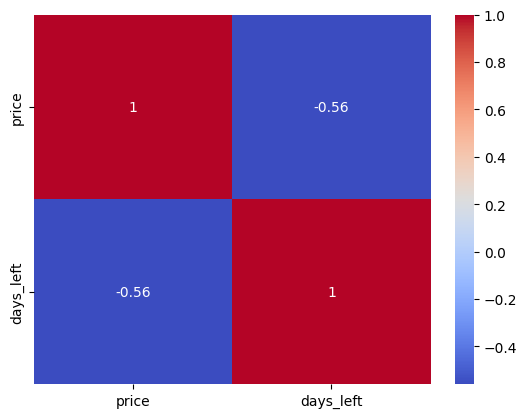

In [22]:
sns.heatmap(corr1.corr(),annot=True,cmap='coolwarm')

<Axes: xlabel='days_left', ylabel='price'>

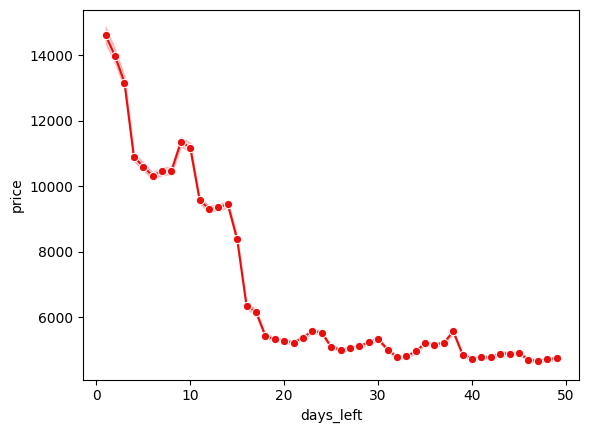

In [23]:
sns.lineplot(data=corr1,x='days_left',y='price',color='#e80e0e',marker='o')


<Axes: xlabel='duration', ylabel='Count'>

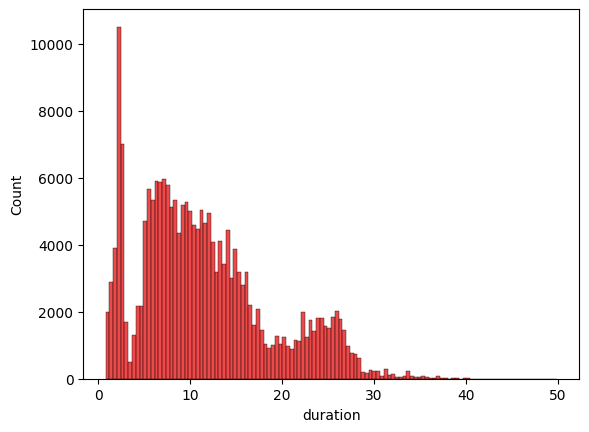

In [24]:
sns.histplot(df['duration'],bins=120,color='#e80e0e')

In [25]:
df['duration'].agg(['min','max','mean','median','std'])

min        0.830000
max       49.830000
mean      11.550060
median    10.170000
std        7.241284
Name: duration, dtype: float64

In [26]:
dur=df[df['duration']<10]

<Axes: xlabel='duration', ylabel='Density'>

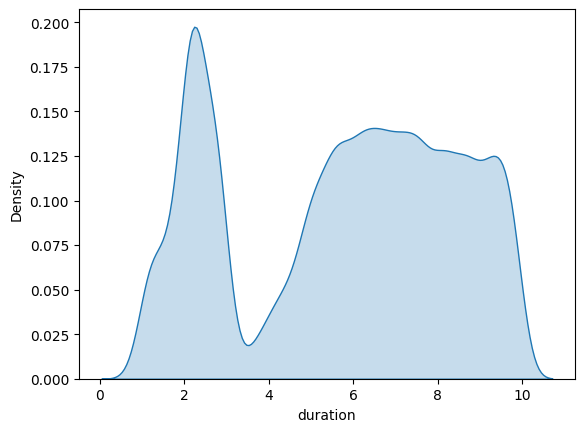

In [27]:
sns.kdeplot(dur['duration'],fill=True)

In [28]:
dur1=dur[['source_city','destination_city']].value_counts().reset_index().sort_values(by='count',ascending=False)

<Axes: xlabel='count', ylabel='source_city'>

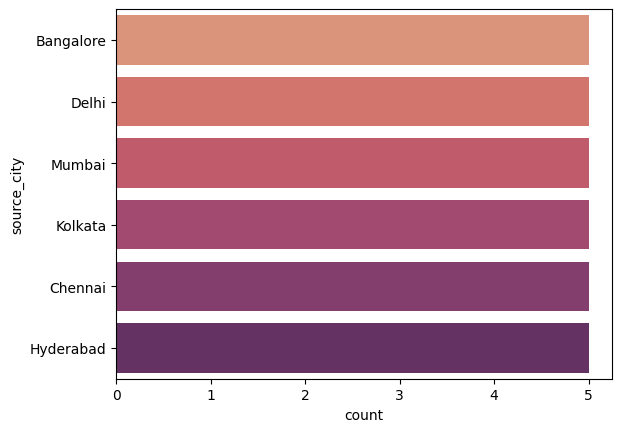

In [29]:
sns.countplot(data=dur1,y='source_city',palette='flare')

<Axes: xlabel='count', ylabel='destination_city'>

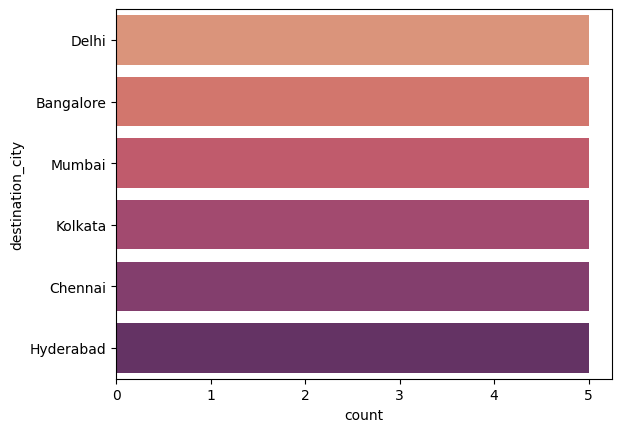

In [30]:
sns.countplot(data=dur1,y='destination_city',palette='flare')

In [31]:
df[['price','duration']].corr()

,price,duration
price,1.000000,0.288379
duration,0.288379,1.000000


<Axes: >

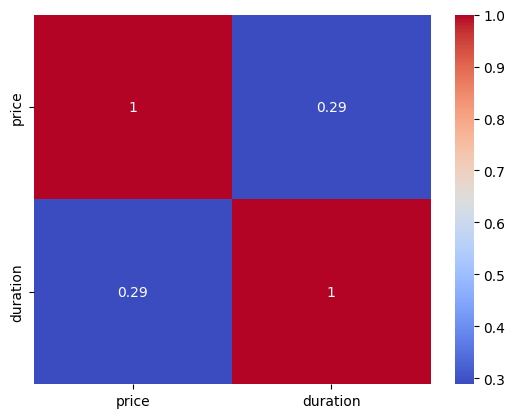

In [32]:
sns.heatmap(df[['price','duration']].corr(),annot=True,cmap='coolwarm')

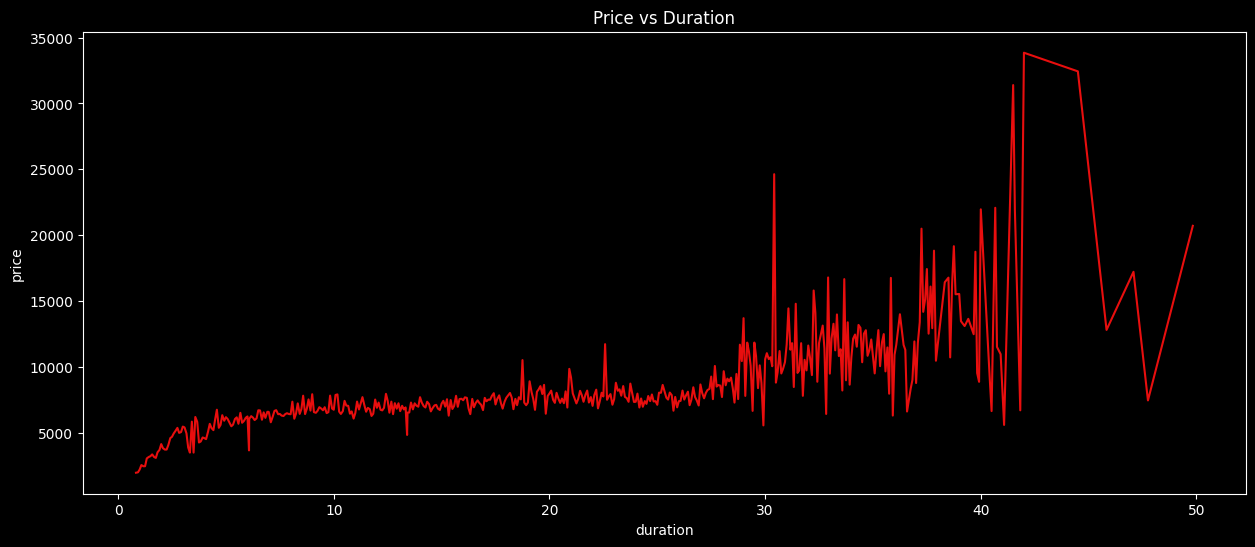

In [33]:
plt.style.use('dark_background')
plt.figure(figsize=(15,6))
sns.lineplot(data=df,x='duration',y='price',color='#e80e0e',ci=None)
plt.title('Price vs Duration')
plt.show()

In [34]:
dur2=df[df['duration']>24]

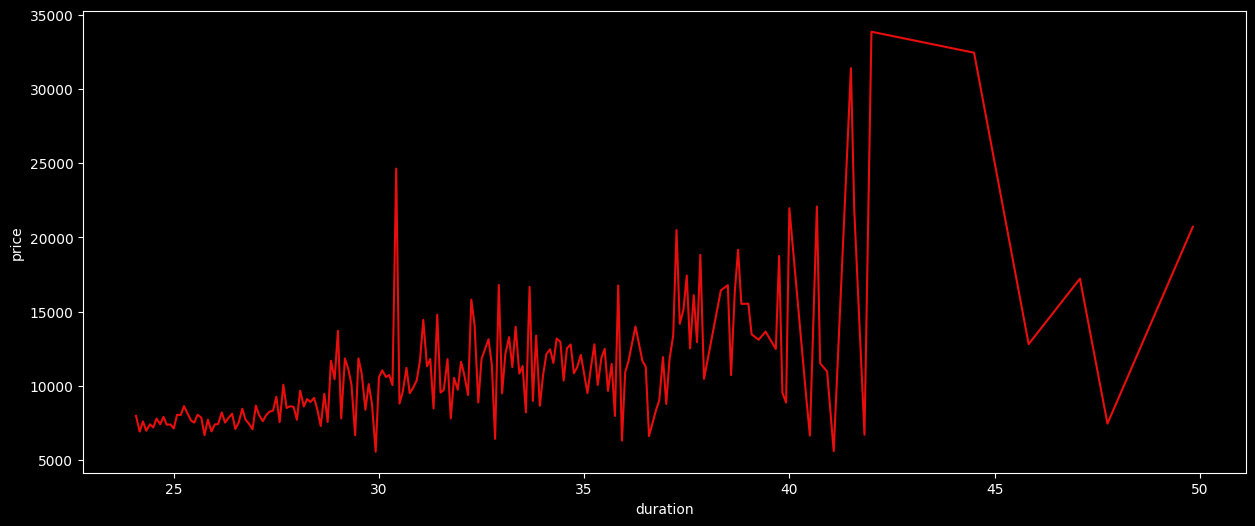

In [35]:
plt.figure(figsize=(15,6))
sns.lineplot(data=dur2,x='duration',y='price',color='#e80e0e',ci=None)
plt.show()

<Axes: xlabel='duration', ylabel='price'>

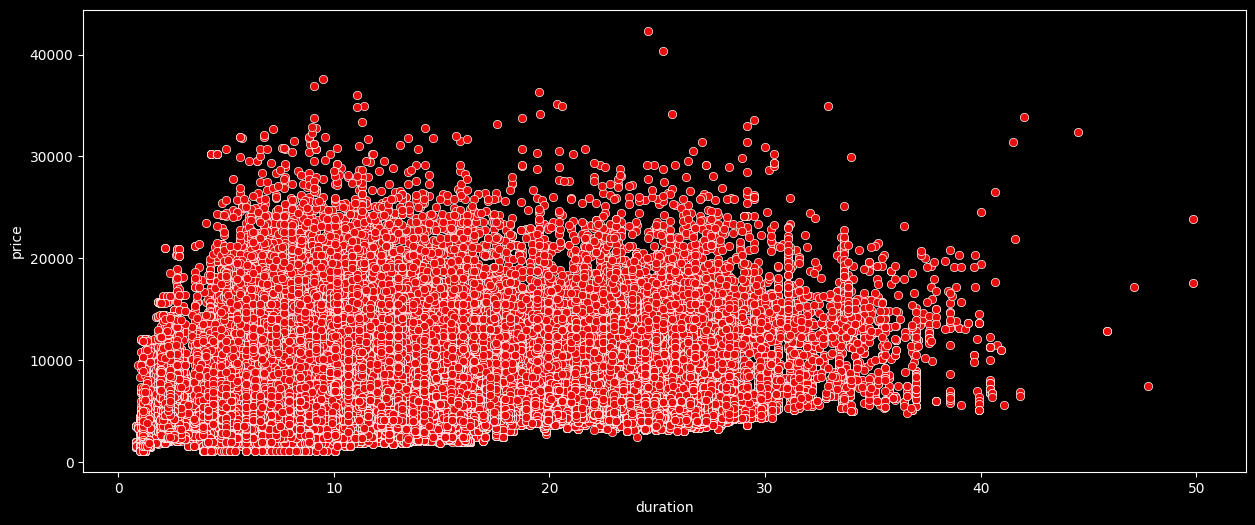

In [36]:
plt.figure(figsize=(15,6))
sns.scatterplot(data=df,x='duration',y='price',color='#e80e0e')

In [37]:
df['class'].value_counts()

class
Economy    206666
Name: count, dtype: int64

In [38]:
df['arrival_time'].value_counts()

arrival_time
Night            62513
Evening          51924
Morning          40949
Afternoon        27209
Late_Night       12168
Early_Morning    11903
Name: count, dtype: int64

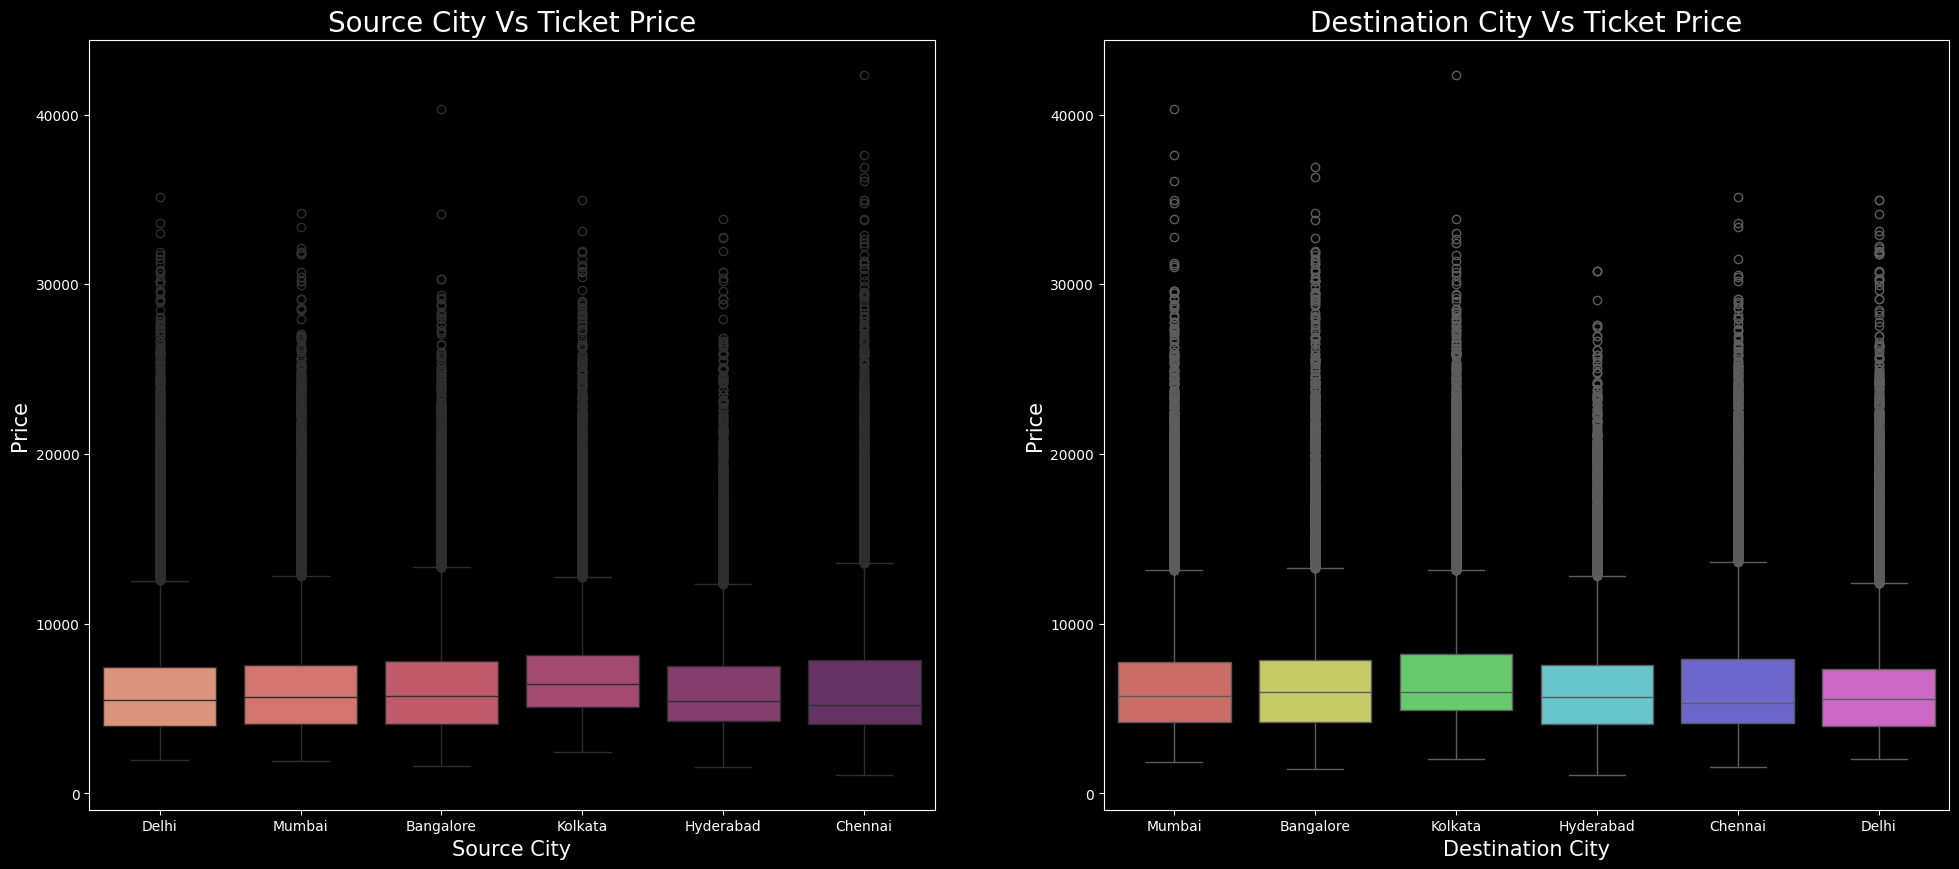

In [39]:
plt.figure(figsize=(24,10))
plt.subplot(1,2,1)
sns.boxplot(x='source_city',y='price',data=df,palette='flare')
plt.title('Source City Vs Ticket Price',fontsize=20)
plt.xlabel('Source City',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.subplot(1,2,2)
sns.boxplot(x='destination_city',y='price',data=df,palette='hls')
plt.title('Destination City Vs Ticket Price',fontsize=20)
plt.xlabel('Destination City',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

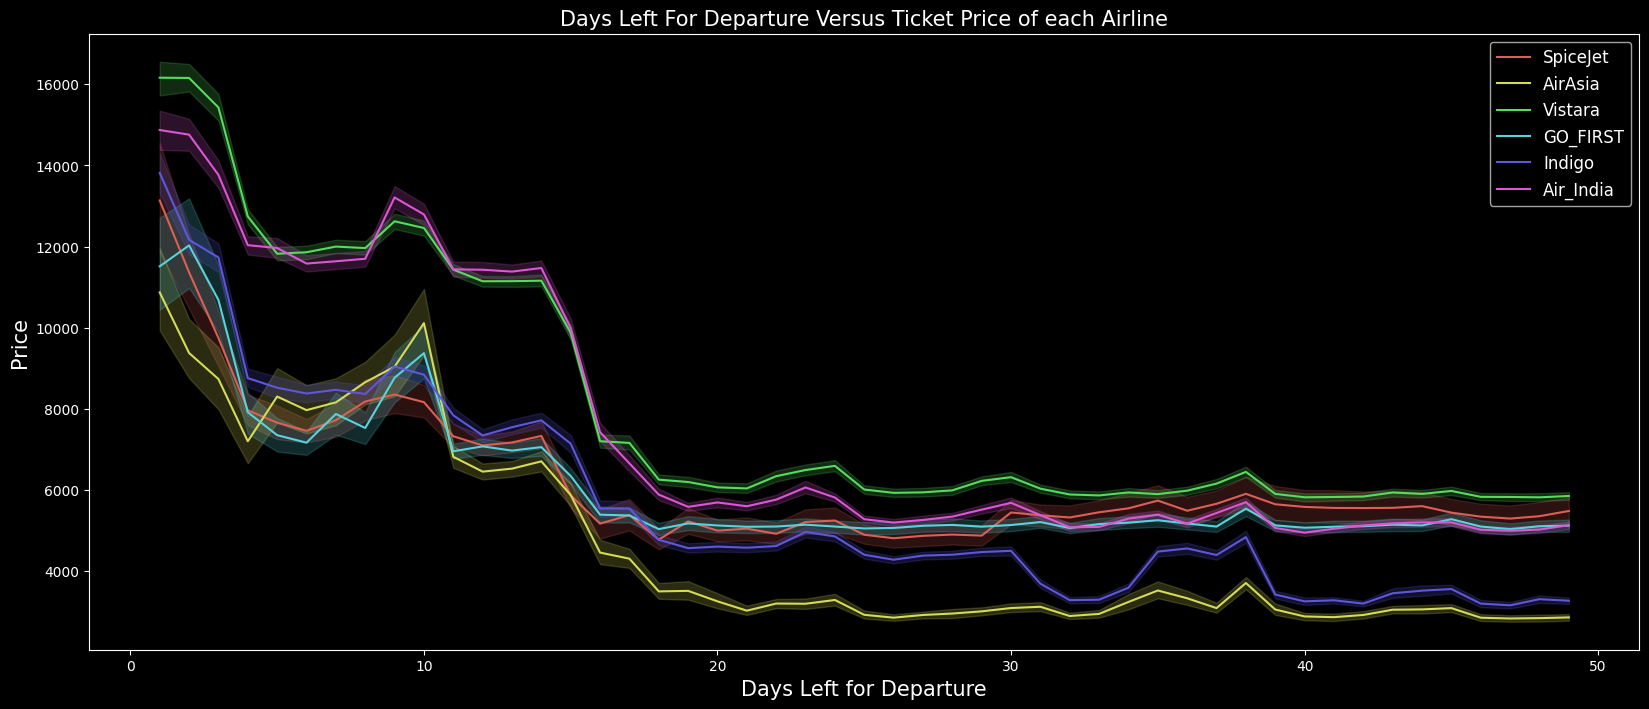

In [40]:
plt.figure(figsize=(20,8))
sns.lineplot(data=df,x='days_left',y='price',color='blue',hue='airline',palette='hls')
plt.title('Days Left For Departure Versus Ticket Price of each Airline',fontsize=15)
plt.legend(fontsize=12)
plt.xlabel('Days Left for Departure',fontsize=15)
plt.ylabel('Price',fontsize=15)
plt.show()

<Axes: xlabel='count', ylabel='arrival_time'>

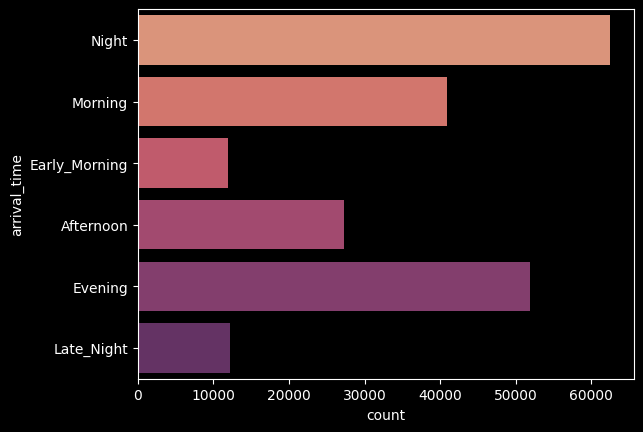

In [41]:
sns.countplot(df['arrival_time'],palette='flare')

In [42]:
df[['duration','price']].corr()

,duration,price
duration,1.000000,0.288379
price,0.288379,1.000000


<Axes: >

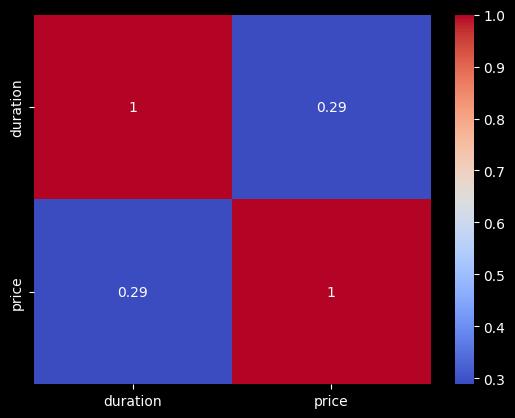

In [43]:
sns.heatmap(df[['duration','price']].corr(),annot=True,cmap='coolwarm')

In [44]:
df['airline'].value_counts()

airline
Vistara      67270
Air_India    47994
Indigo       43120
GO_FIRST     23173
AirAsia      16098
SpiceJet      9011
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='airline'>

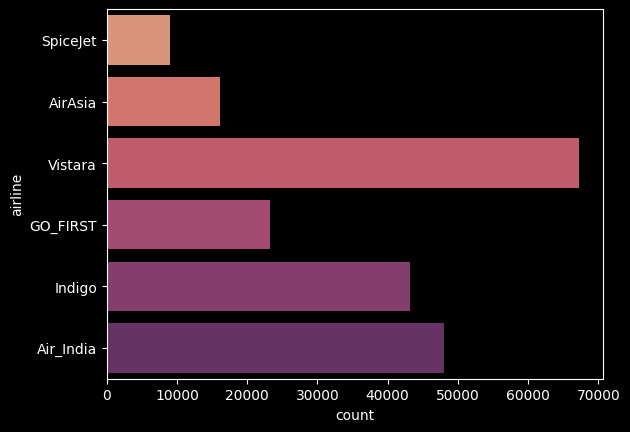

In [45]:
sns.countplot(df['airline'],palette='flare')

In [46]:
# airline is a text column, so .corr() doesn't work - compare average fares instead
df.groupby('airline')['price'].agg(['mean','median','count']).sort_values('mean',ascending=False)

,mean,median,count
airline,,,
Vistara,7806.943645,6461.0,67270
Air_India,7313.682169,6082.0,47994
SpiceJet,6179.278881,5654.0,9011
GO_FIRST,5652.007595,5336.0,23173
Indigo,5324.216303,4453.0,43120
AirAsia,4091.072742,3276.0,16098


In [47]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [48]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [49]:
le=LabelEncoder()
for col in df.columns:
    if df[col].dtype=='object':
        df[col]=le.fit_transform(df[col])

In [50]:
y=df['price']
x=df.drop(['price','Unnamed: 0'],axis=1)   # Unnamed: 0 is just the row index, not a feature

In [51]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [52]:
# Scaling the values (fit on train only, then apply the same scaling to test)
from sklearn.preprocessing import MinMaxScaler
mmscaler=MinMaxScaler(feature_range=(0,1))
x_train=mmscaler.fit_transform(x_train)
x_test=mmscaler.transform(x_test)
x_train=pd.DataFrame(x_train)
x_test=pd.DataFrame(x_test)

In [53]:
mod1=LinearRegression()
mod1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [54]:
mod1.score(x_train,y_train)

0.4179607320557214

In [55]:
mod1.score(x_test,y_test)

0.4189473894401252

In [56]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor()
rf.fit(x_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [57]:
rf.score(x_train,y_train)

0.9839175367440652

In [58]:
rf.score(x_test,y_test)

0.8942117495773236

In [59]:
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn import linear_model
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
import xgboost as xgb
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.ensemble import GradientBoostingRegressor
import pandas as pd # Import pandas for DataFrame initialization
import numpy as np # Import numpy for calculations like sqrt and log
from sklearn import metrics # Import metrics for evaluation

# Create objects of Regression / Regressor models with default hyper-parameters

modelmlg = LinearRegression()
modeldcr = DecisionTreeRegressor()
modelbag = BaggingRegressor()
modelrfr = RandomForestRegressor()
modelSVR = SVR()
modelXGR = xgb.XGBRegressor()
modelKNN = KNeighborsRegressor(n_neighbors=5)
modelETR = ExtraTreesRegressor()
modelRE=Ridge()
modelLO=linear_model.Lasso(alpha=0.1)

modelGBR = GradientBoostingRegressor(loss='squared_error', learning_rate=0.1, n_estimators=100, subsample=1.0,
                                     criterion='friedman_mse', min_samples_split=2, min_samples_leaf=1,
                                     min_weight_fraction_leaf=0.0, max_depth=3, min_impurity_decrease=0.0,
                                     init=None, random_state=None, max_features=None,
                                     alpha=0.9, verbose=0, max_leaf_nodes=None, warm_start=False,
                                     validation_fraction=0.1, n_iter_no_change=None, tol=0.0001, ccp_alpha=0.0)

# Evalution matrix for all the algorithms

MM = [modelmlg, modeldcr, modelrfr, modelKNN, modelETR, modelGBR, modelXGR, modelbag,modelRE,modelLO]

# Initialize an empty list to store results
results_list = []

for models in MM:

    # Fit the model with train data

    models.fit(x_train, y_train)

    # Predict the model with test data

    y_pred = models.predict(x_test)

    # Print the model name

    print('Model Name: ', models)

    # Evaluation metrics for Regression analysis


    print('Mean Absolute Error (MAE):', round(metrics.mean_absolute_error(y_test, y_pred),3))
    print('Mean Squared Error (MSE):', round(metrics.mean_squared_error(y_test, y_pred),3))
    print('Root Mean Squared Error (RMSE):', round(np.sqrt(metrics.mean_squared_error(y_test, y_pred)),3))
    print('R2_score:', round(metrics.r2_score(y_test, y_pred),6))
    # Handle potential negative values from MSE before taking log
    if metrics.mean_squared_error(y_test, y_pred) > 0:
        print('Root Mean Squared Log Error (RMSLE):', round(np.log(np.sqrt(metrics.mean_squared_error(y_test, y_pred))),3))
    else:
         print('Root Mean Squared Log Error (RMSLE):', float('-inf')) # Or handle as appropriate


    # Define the function to calculate the MAPE - Mean Absolute Percentage Error

    def MAPE (y_test, y_pred):
        y_test, y_pred = np.array(y_test), np.array(y_pred)
        # Avoid division by zero
        return np.mean(np.abs((y_test - y_pred) / y_test)) * 100 if not np.any(y_test == 0) else np.nan


    # Evaluation of MAPE

    result = MAPE(y_test, y_pred)
    print('Mean Absolute Percentage Error (MAPE):', round(result, 2), '%')

    # Calculate Adjusted R squared values

    r_squared = round(metrics.r2_score(y_test, y_pred),6)
    # Avoid division by zero in adjusted R-squared calculation
    if (len(y)-x.shape[1]-1) != 0:
        adjusted_r_squared = round(1 - (1-r_squared)*(len(y)-1)/(len(y)-x.shape[1]-1),6)
    else:
        adjusted_r_squared = np.nan # Or handle as appropriate
    print('Adj R Square: ', adjusted_r_squared)
    print('------------------------------------------------------------------------------------------------------------')
    #-------------------------------------------------------------------------------------------
    new_row = {'Model Name' : type(models).__name__,
               'Mean_Absolute_Error_MAE' : metrics.mean_absolute_error(y_test, y_pred),
               'Adj_R_Square' : adjusted_r_squared,
               'Root_Mean_Squared_Error_RMSE' : np.sqrt(metrics.mean_squared_error(y_test, y_pred)),
               'Mean_Absolute_Percentage_Error_MAPE' : result,
               'Mean_Squared_Error_MSE' : metrics.mean_squared_error(y_test, y_pred),
               'Root_Mean_Squared_Log_Error_RMSLE': np.log(np.sqrt(metrics.mean_squared_error(y_test, y_pred))) if metrics.mean_squared_error(y_test, y_pred) > 0 else float('-inf'),
               'R2_score' : metrics.r2_score(y_test, y_pred)}
    # Append the new row dictionary to the list
    results_list.append(new_row)

# Convert the list of dictionaries to a DataFrame after the loop
Results = pd.DataFrame(results_list)

Model Name:  LinearRegression()
Mean Absolute Error (MAE): 2065.923
Mean Squared Error (MSE): 7955746.992
Root Mean Squared Error (RMSE): 2820.593
R2_score: 0.418947
Root Mean Squared Log Error (RMSLE): 7.945
Mean Absolute Percentage Error (MAPE): 37.54 %
Adj R Square:  0.418919
------------------------------------------------------------------------------------------------------------


Model Name:  DecisionTreeRegressor()
Mean Absolute Error (MAE): 539.656
Mean Squared Error (MSE): 2563336.346
Root Mean Squared Error (RMSE): 1601.042
R2_score: 0.812785
Root Mean Squared Log Error (RMSLE): 7.378
Mean Absolute Percentage Error (MAPE): 7.17 %
Adj R Square:  0.812776
------------------------------------------------------------------------------------------------------------


Model Name:  RandomForestRegressor()
Mean Absolute Error (MAE): 502.753
Mean Squared Error (MSE): 1447467.806
Root Mean Squared Error (RMSE): 1203.108
R2_score: 0.894283
Root Mean Squared Log Error (RMSLE): 7.093
Mean Absolute Percentage Error (MAPE): 7.02 %
Adj R Square:  0.894278
------------------------------------------------------------------------------------------------------------


Model Name:  KNeighborsRegressor()
Mean Absolute Error (MAE): 843.87
Mean Squared Error (MSE): 2618307.695
Root Mean Squared Error (RMSE): 1618.119
R2_score: 0.80877
Root Mean Squared Log Error (RMSLE): 7.389
Mean Absolute Percentage Error (MAPE): 12.27 %
Adj R Square:  0.808761
------------------------------------------------------------------------------------------------------------


Model Name:  ExtraTreesRegressor()
Mean Absolute Error (MAE): 537.491
Mean Squared Error (MSE): 1579457.286
Root Mean Squared Error (RMSE): 1256.765
R2_score: 0.884643
Root Mean Squared Log Error (RMSLE): 7.136
Mean Absolute Percentage Error (MAPE): 7.61 %
Adj R Square:  0.884637
------------------------------------------------------------------------------------------------------------


Model Name:  GradientBoostingRegressor()
Mean Absolute Error (MAE): 1315.327
Mean Squared Error (MSE): 4027576.423
Root Mean Squared Error (RMSE): 2006.882
R2_score: 0.705844
Root Mean Squared Log Error (RMSLE): 7.604
Mean Absolute Percentage Error (MAPE): 21.81 %
Adj R Square:  0.70583
------------------------------------------------------------------------------------------------------------


Model Name:  XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)
Mean Absolute Error (MAE): 917.109
Mean Squared Error (MSE): 2320646.5
Root Mean Squared Error (RMSE): 1523.367
R2_score: 0.83051
Root Mean Squared Log Error (RMSLE): 7.329
Mean Absolute Percentage Error (MAPE): 14.47 %
Adj R Square:  0.8

Model Name:  BaggingRegressor()
Mean Absolute Error (MAE): 528.695
Mean Squared Error (MSE): 1607634.31
Root Mean Squared Error (RMSE): 1267.925
R2_score: 0.882585
Root Mean Squared Log Error (RMSLE): 7.145
Mean Absolute Percentage Error (MAPE): 7.34 %
Adj R Square:  0.882579
------------------------------------------------------------------------------------------------------------
Model Name:  Ridge()
Mean Absolute Error (MAE): 2065.904
Mean Squared Error (MSE): 7955734.521
Root Mean Squared Error (RMSE): 2820.591
R2_score: 0.418948
Root Mean Squared Log Error (RMSLE): 7.945
Mean Absolute Percentage Error (MAPE): 37.54 %
Adj R Square:  0.41892
------------------------------------------------------------------------------------------------------------
Model Name:  Lasso(alpha=0.1)
Mean Absolute Error (MAE): 2065.89
Mean Squared Error (MSE): 7955719.482
Root Mean Squared Error (RMSE): 2820.588
R2_score: 0.418949
Root Mean Squared Log Error (RMSLE): 7.945
Mean Absolute Percentage Error 

In [60]:
Results.sort_values('R2_score',ascending=False)

,Model Name,Mean_Absolute_Error_MAE,Adj_R_Square,Root_Mean_Squared_Error_RMSE,Mean_Absolute_Percentage_Error_MAPE,Mean_Squared_Error_MSE,Root_Mean_Squared_Log_Error_RMSLE,R2_score
2,RandomForestRegressor,502.753451,0.894278,1203.107562,7.022300,1.447468e+06,7.092663,0.894283
4,ExtraTreesRegressor,537.491190,0.884637,1256.764610,7.607915,1.579457e+06,7.136296,0.884643
7,BaggingRegressor,528.695454,0.882579,1267.925199,7.335577,1.607634e+06,7.145137,0.882585
6,XGBRegressor,917.108643,0.830502,1523.366830,14.465834,2.320646e+06,7.328678,0.830510
1,DecisionTreeRegressor,539.656159,0.812776,1601.042269,7.168072,2.563336e+06,7.378410,0.812785
3,KNeighborsRegressor,843.870238,0.808761,1618.118566,12.274626,2.618308e+06,7.389019,0.808770
5,GradientBoostingRegressor,1315.326912,0.705830,2006.882264,21.813684,4.027576e+06,7.604338,0.705844
9,Lasso,2065.889642,0.418921,2820.588499,37.538402,7.955719e+06,7.944701,0.418949
8,Ridge,2065.904256,0.418920,2820.591165,37.537817,7.955735e+06,7.944702,0.418948
0,LinearRegression,2065.922674,0.418919,2820.593376,37.538017,7.955747e+06,7.944703,0.418947


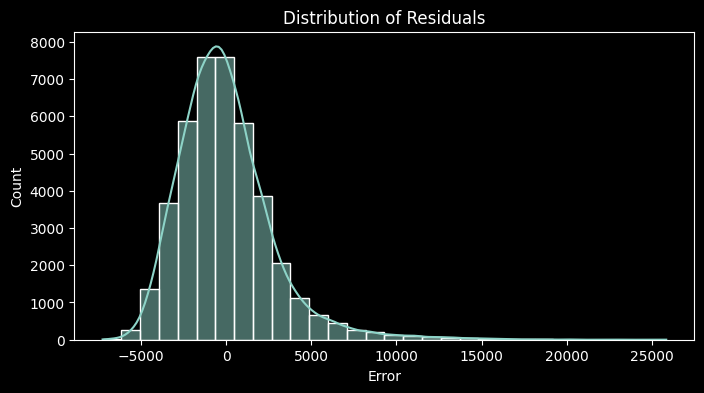

In [61]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=30, kde=True)
plt.title("Distribution of Residuals")
plt.xlabel("Error")
plt.show()